In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [11]:
trametes = pd.read_csv("trametes_datasets_summary.csv")
methanococcus = pd.read_csv("methanococcus_datasets_summary.csv")
borrelia = pd.read_csv("borrelia_datasets_summary.csv")

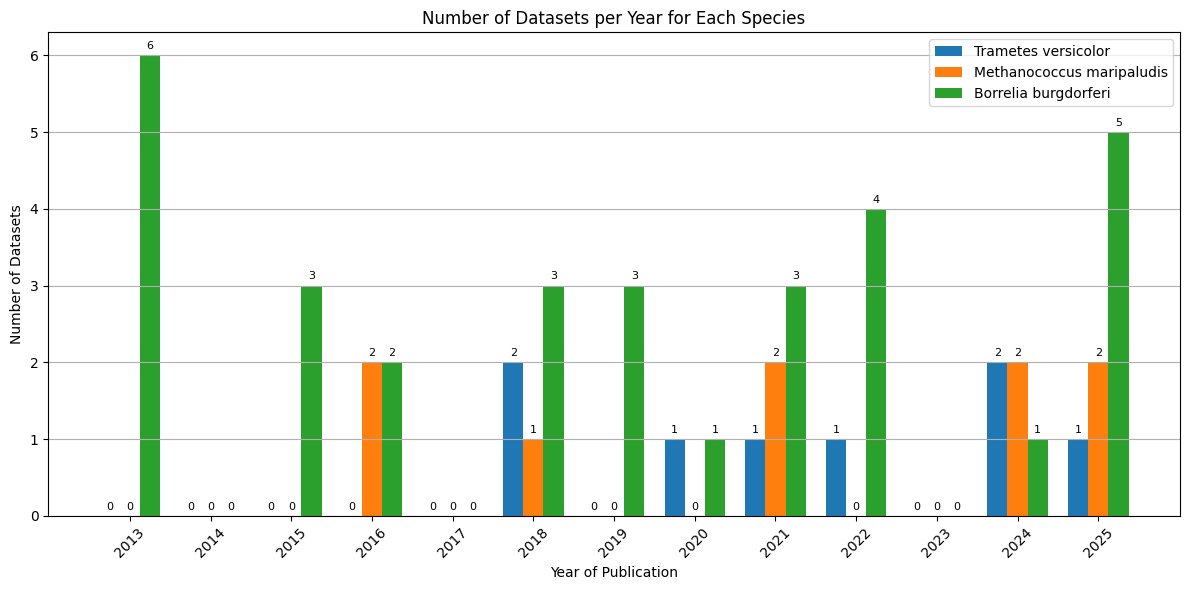

In [ ]:
# Define the full range of years
all_years = pd.Index(range(2013, 2026))
all_years_str = all_years.astype(str)

# Get year counts for each species, ensuring all years are represented
trametes_year_counts = trametes['Year'].value_counts().sort_index().reindex(all_years, fill_value=0)
methanococcus_year_counts = methanococcus['Year'].value_counts().sort_index().reindex(all_years, fill_value=0)
borrelia_year_counts = borrelia['Year'].value_counts().sort_index().reindex(all_years, fill_value=0)

# Set up bar positions
x = np.arange(len(all_years))
width = 0.25

# Create grouped bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(x - width, trametes_year_counts.values, width, label='Trametes versicolor')
bars2 = plt.bar(x, methanococcus_year_counts.values, width, label='Methanococcus maripaludis')
bars3 = plt.bar(x + width, borrelia_year_counts.values, width, label='Borrelia burgdorferi')

# Add value labels above bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.annotate(f'{int(height)}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=8)

plt.xlabel('Year of Publication')
plt.ylabel('Number of Datasets')
plt.title('Number of Datasets per Year for Each Species')
plt.xticks(x, all_years_str, rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(axis='y')
plt.savefig("datasets_per_year_comparison.jpg", dpi=300)  # Save the figure as a .jpg file
plt.show()